#Deep Learning para visión de computadoras
##Lab 2.3 Redes recurrentes en visión

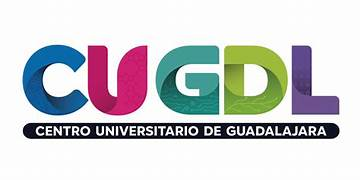

•	Video como secuencia de frames
•	Arquitectura CNN-LSTM para procesamiento temporal
•	Aplicación: clasificación de acciones en video
•	Comparativa: CNN estática versus CNN-LSTM


## Librerías



In [1]:
import time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 3
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

ACCIONES = ["derecha", "izquierda", "arriba", "abajo", "giro horario", "giro antihorario"]
N_CLASES = len(ACCIONES)
TAM, T = 32, 16        # frames de 32 x 32 píxeles, 16 frames por video

Dispositivo: cuda · Tesla T4
torch 2.11.0+cu130


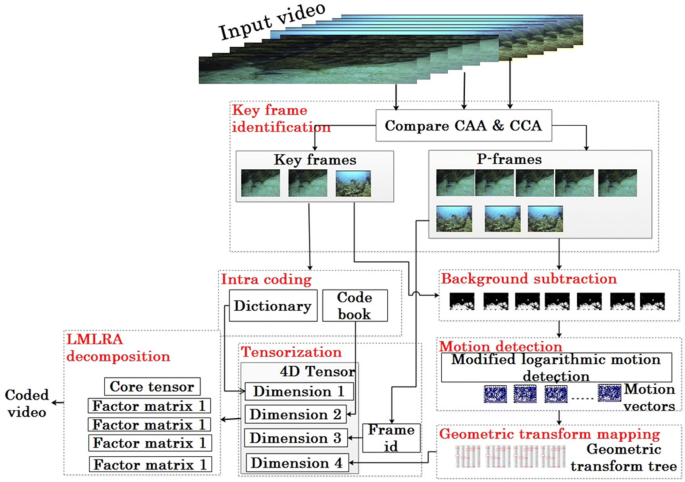

https://link.springer.com/article/10.1007/s11277-019-06704-4

---
# PARTE A
Un video es un tensor con una dimensión más

Una imagen en escala de grises es un tensor $(1, H, W)$. Un video de $T$ frames es $(T, 1, H, W)$, y un lote de videos es $(B, T, 1, H, W)$. Las seis acciones son:

| Acciones | Qué ocurre | Qué distingue una de otra |
|---|---|---|
| `derecha`, `izquierda`, `arriba`, `abajo` | La pelota cruza la imagen en línea recta | **Sentido** del desplazamiento |
| `giro horario`, `giro antihorario` | La pelota recorre una circunferencia | **Sentido** de giro |

Entrenamiento: (1200, 16, 1, 32, 32) = (videos, frames, canales, alto, ancho)
Validación   : (300, 16, 1, 32, 32)
Tamaño en memoria del entrenamiento: 79 MB


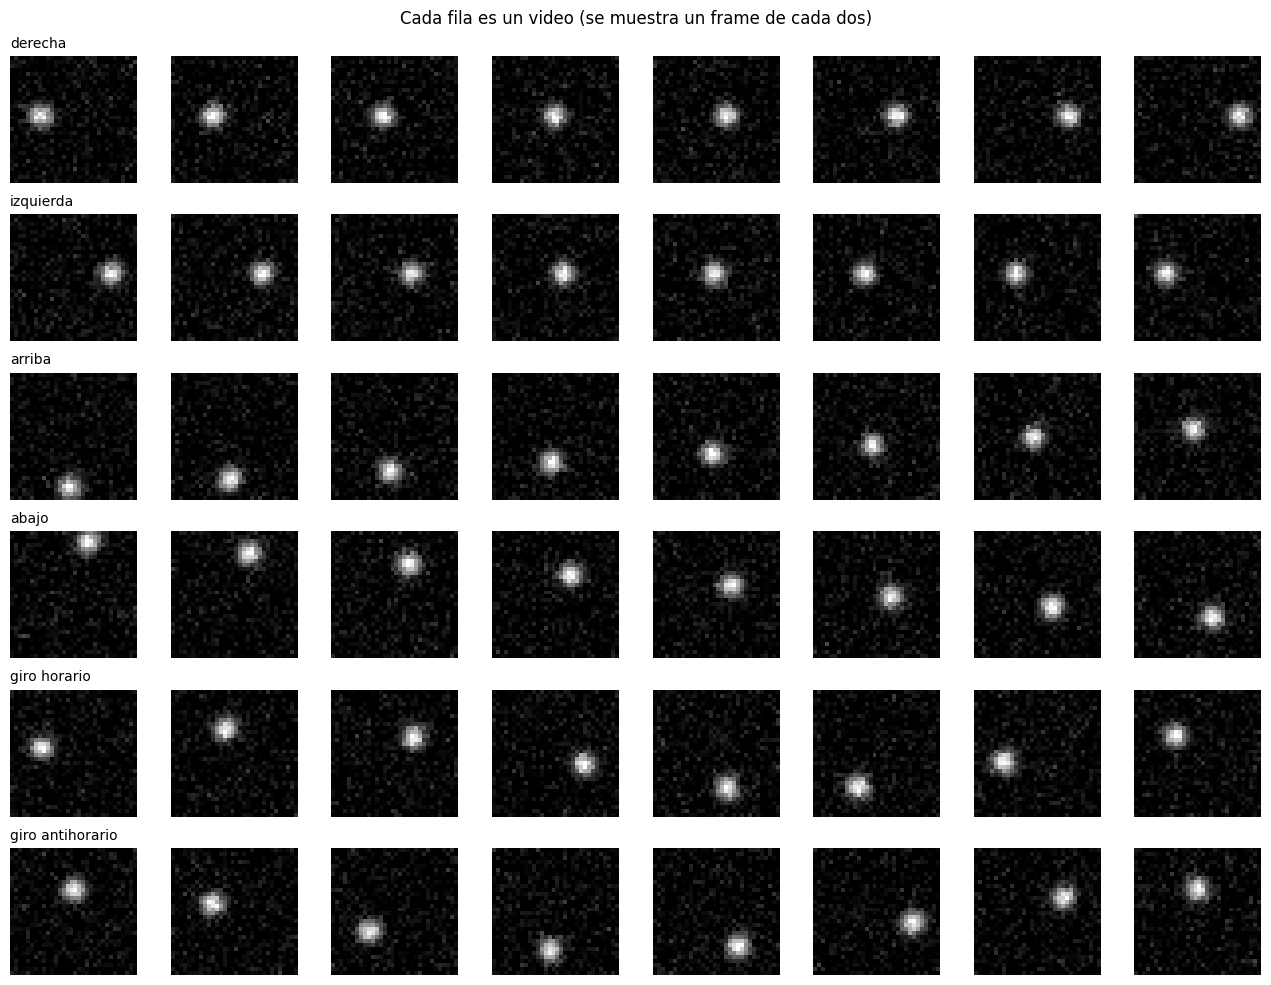

In [2]:
def generar_video(rng, clase, T=T, tam=TAM):
    yy, xx = np.mgrid[0:tam, 0:tam].astype(np.float32)
    v = rng.uniform(1.0, 1.4)
    jit = rng.uniform(-4, 4, 2)
    t = np.arange(T)
    c = tam / 2
    if clase < 4:
        dx, dy = [(1, 0), (-1, 0), (0, -1), (0, 1)][clase]
        cx = c + jit[0] + dx * v * (t - T / 2); cy = c + jit[1] + dy * v * (t - T / 2)
    else:
        sentido = 1 if clase == 4 else -1
        fase = rng.uniform(0, 2 * np.pi); w = rng.uniform(0.35, 0.5)   # radianes por frame
        cx = c + jit[0] * 0.5 + 8 * np.cos(fase + sentido * w * t); cy = c + jit[1] * 0.5 + 8 * np.sin(fase + sentido * w * t)
    frames = np.exp(-((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2) / (2 * 2.0 ** 2))
    frames = frames + rng.normal(0, 0.08, frames.shape)
    return np.clip(frames, 0, 1).astype(np.float32)[:, None]      # (T, 1, H, W)

def generar_dataset(n_por_clase, semilla):
    rng = np.random.default_rng(semilla)
    X, Y = [], []
    for clase in range(N_CLASES):
        for _ in range(n_por_clase):
            X.append(generar_video(rng, clase)); Y.append(clase)
    X, Y = torch.tensor(np.stack(X)), torch.tensor(Y)
    p = torch.randperm(len(X), generator=torch.Generator().manual_seed(semilla))
    return X[p], Y[p]

X_ent, Y_ent = generar_dataset(200, semilla=1)
X_val, Y_val = generar_dataset(50, semilla=2)
print("Entrenamiento:", tuple(X_ent.shape), "= (videos, frames, canales, alto, ancho)")
print("Validación   :", tuple(X_val.shape))
print(f"Tamaño en memoria del entrenamiento: {X_ent.numel()*4/1e6:.0f} MB")

fig, ax = plt.subplots(6, 8, figsize=(13, 10))
for c in range(N_CLASES):
    i = int((Y_ent == c).nonzero()[0])
    for j, t in enumerate(range(0, T, 2)):
        ax[c, j].imshow(X_ent[i, t, 0], cmap="gray", vmin=0, vmax=1); ax[c, j].axis("off")
        if j == 0: ax[c, j].set_title(ACCIONES[c], loc="left", fontsize=10)
plt.suptitle("Cada fila es un video (se muestra un frame de cada dos)"); plt.tight_layout(); plt.show()

¿Qué observaste? Explica por qué, para clasificar la acción en `derecha` vs. `izquierda`, se necesita comparar **al menos dos frames**.

¿Cuántos números tiene un video de este conjunto? ¿Y un video de 10 s a 30 fps y 224×224 RGB? Calcula el tamaño en MB (float32) y comenta qué implica para el lote que cabe en la GPU.

### Respuestas a las Preguntas de la Parte A

#### 1. ¿Por qué se necesita comparar al menos dos frames para clasificar la acción `derecha` vs. `izquierda`?
Una sola imagen estática (un solo frame) únicamente nos da la información espacial de la pelota en un instante $t$ concreto. Si vemos una pelota en el centro de la imagen, no tenemos forma de saber si se está moviendo hacia la derecha o hacia la izquierda.

Para poder determinar la **dirección y sentido del movimiento** (la velocidad y el desplazamiento temporal $dx/dt$), obligatoriamente necesitamos conocer la posición de la pelota en al menos dos instantes de tiempo distintos ($t_1$ y $t_2$). Al comparar las posiciones de la pelota entre estos dos frames, podemos determinar si el valor de su coordenada en el eje X está incrementándose (movimiento a la derecha) o disminuyendo (movimiento a la izquierda).

----

#### 2. Cálculos de tamaño de video y almacenamiento en memoria (float32)

##### A) Un video de este conjunto artificial
* **Dimensiones del tensor:** $T \times C \times H \times W = 16 \text{ frames} \times 1 \text{ canal} \times 32 \text{ alto} \times 32 \text{ ancho}$
* **Cantidad de números (parámetros/píxeles):**
  $$\text{Números} = 16 \times 1 \times 32 \times 32 = 16,384 \text{ valores}$$
* **Tamaño en memoria (float32, 4 bytes por número):**
  $$\text{Tamaño} = 16,384 \times 4 \text{ bytes} = 65,536 \text{ bytes} \approx 65.5 \text{ KB} \approx 0.065 \text{ MB}$$

##### B) Un video de 10 s a 30 fps y $224 \times 224$ RGB
* **Frames totales ($T$):** $10 \text{ s} \times 30 \text{ fps} = 300 \text{ frames}$
* **Canales ($C$):** $3 \text{ (RGB)}$
* **Dimensiones del tensor:** $300 \times 3 \times 224 \times 224$
* **Cantidad de números:**
  $$\text{Números} = 300 \times 3 \times 224 \times 224 = 45,158,400 \text{ valores}$$
* **Tamaño en memoria (float32, 4 bytes por número):**
  $$\text{Tamaño} = 45,158,400 \times 4 \text{ bytes} = 180,633,600 \text{ bytes} \approx 180.63 \text{ MB}$$

#### ¿Qué implica esto para el lote (batch) que cabe en la GPU?
* **Carga masiva de datos:** Un único video de alta resolución ya consume $180 \text{ MB}$ solo para almacenar el dato de entrada. Si procesamos un batch típico de $32$ videos, la entrada pura representará más de $5.7 \text{ GB}$ de memoria.
* **Picos de memoria por activaciones:** Al realizar el forward pass de la red (especialmente las capas convolucionales que expanden los canales), los mapas de características intermedios para cada frame y cada elemento del batch deben guardarse en la memoria de la GPU para calcular los gradientes (backpropagation). Esto multiplica el requisito de memoria por un factor de 5 a 10.
* **Limitación del tamaño de lote (Batch Size):** En GPUs de consumo o intermedias (como una Tesla T4 de 15 o 16 GB), un batch de tamaño regular con videos reales a resolución completa causará rápidamente un error de falta de memoria (**Out of Memory - OOM**). Esto obliga a los ingenieros de visión a usar tamaños de lote muy pequeños (ej. 2, 4 u 8), a usar submuestreo temporal (ej. tomar un frame de cada diez) o a disminuir drásticamente la resolución espacial de los frames.

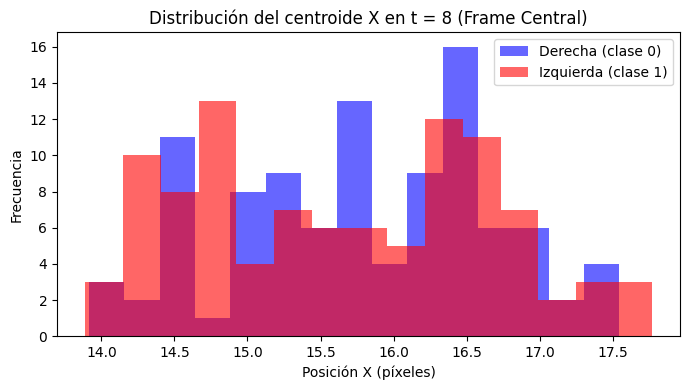

In [3]:
def centroide_x(frame):                      # frame: (1, H, W)
    f = frame[0]; xs = torch.arange(f.shape[1]).float()
    return float((f.sum(0) * xs).sum() / (f.sum() + 1e-8))

indices_der = (Y_ent == 0).nonzero().flatten()[:100]
indices_izq = (Y_ent == 1).nonzero().flatten()[:100]

cx_derecha = [centroide_x(X_ent[i, 8]) for i in indices_der]
cx_izquierda = [centroide_x(X_ent[i, 8]) for i in indices_izq]

plt.figure(figsize=(7, 4))
plt.hist(cx_derecha, bins=15, alpha=0.6, label="Derecha (clase 0)", color="blue")
plt.hist(cx_izquierda, bins=15, alpha=0.6, label="Izquierda (clase 1)", color="red")
plt.title("Distribución del centroide X en t = 8 (Frame Central)")
plt.xlabel("Posición X (píxeles)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

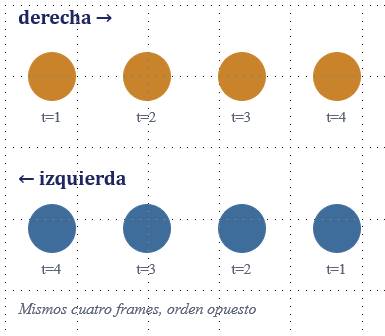

# Long-Short Term Memory (LSTM)

Las unidades de memoria a largo y corto plazo (LSTM, por sus siglas en inglés) son componentes de una red neuronal recurrente. Fueron propuestas por Hochreiter et al. en 1997. Las LSTM se diseñaron para superar el problema del «gradiente desvaneciente», que era inherente a la mayoría de las redes neuronales recurrentes de aquella época. Este problema resulta especialmente grave en secuencias largas (como el texto), ya que ralentiza considerablemente el aprendizaje o, en el peor de los casos, impide la convergencia.

Nota: Estas unidades no resuelven el problema del «gradiente explosivo»; una heurística utilizada habitualmente consiste en recortar los gradientes al alcanzar un determinado umbral.
https://colah.github.io/posts/2015-08-Understanding-LSTMs/

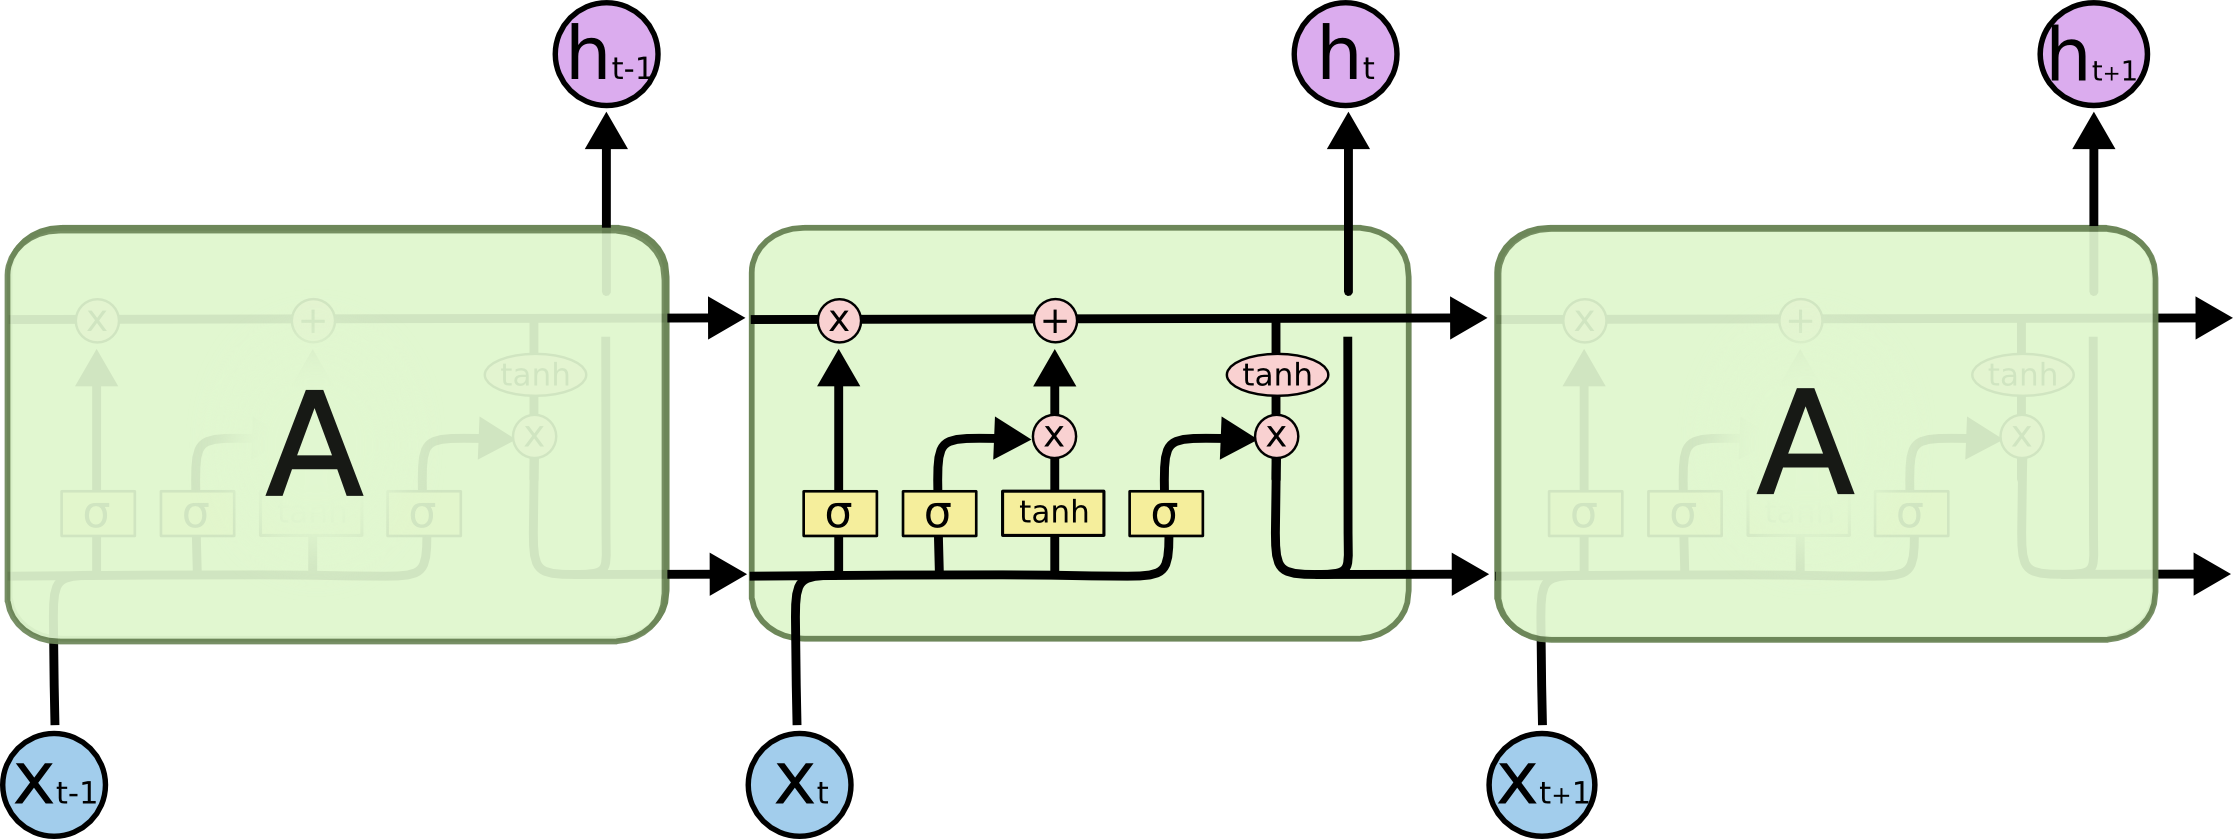

<img src="https://raw.githubusercontent.com/aaubs/ds-master/main/data/Images/LSTM_dynamic.gif" width="600">

---
# PARTE B
Dos modelos CNN-LSTM

Ambos modelos usan **el mismo extractor de características** por frame (una CNN pequeña). Lo único que cambia es qué se hace con las características de cada frame:

* **CNN estática:** clasifica **cada frame por separado**. Un video se clasifica promediando las probabilidades de sus frames (un voto, sin orden).
* **CNN-LSTM:** la CNN produce un vector por frame; una **LSTM** lee los $T$ vectores **en orden** y su último estado oculto se clasifica (añade una memoria con compuertas).

$$\mathbf{f}_t=\mathrm{CNN}(\mathbf{x}_t)\qquad (\mathbf{h}_t,\mathbf{c}_t)=\mathrm{LSTM}(\mathbf{f}_t,\mathbf{h}_{t-1},\mathbf{c}_{t-1})\qquad \hat{y}=\mathrm{softmax}(W\mathbf{h}_T)$$

In [4]:
class CodificadorCNN(nn.Module):
    """Convierte un frame (1x32x32) en un vector de características de tamaño 'dim'."""
    def __init__(self, dim=64):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),     # 16x16
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 8x8
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(2),  # 2x2
            nn.Flatten(), nn.Linear(64 * 4, dim), nn.ReLU())
    def forward(self, x): return self.f(x)

class CNNEstatica(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.cnn = CodificadorCNN(dim); self.clasif = nn.Linear(dim, N_CLASES)
    def forward(self, x):                    # x: (B, T, 1, H, W) → logits por frame (B, T, clases)
        B, T_ = x.shape[:2]
        f = self.cnn(x.flatten(0, 1))        # (B*T, dim): todos los frames como si fueran imágenes sueltas
        return self.clasif(f).view(B, T_, -1)

class CNNLSTM(nn.Module):
    def __init__(self, dim=64, oculto=64):
        super().__init__()
        self.cnn = CodificadorCNN(dim)
        self.lstm = nn.LSTM(dim, oculto, batch_first=True)
        self.clasif = nn.Linear(oculto, N_CLASES)
    def forward(self, x):                    # x: (B, T, 1, H, W) → logits del video (B, clases)
        B, T_ = x.shape[:2]
        f = self.cnn(x.flatten(0, 1)).view(B, T_, -1)    # (B, T, dim): un vector por frame
        salidas, (h, c) = self.lstm(f)                    # la LSTM lee los T vectores EN ORDEN
        return self.clasif(h[-1])                         # último estado oculto → clase

def n_parametros(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
est, lstm = CNNEstatica(), CNNLSTM()
xb = X_ent[:4]
print("Estática: entrada", tuple(xb.shape), "→ salida", tuple(est(xb).shape), "(un resultado por frame)")
print("CNN-LSTM: entrada", tuple(xb.shape), "→ salida", tuple(lstm(xb).shape), "(un resultado por video)")
print(f"Parámetros → CNN estática: {n_parametros(est):,} · CNN-LSTM: {n_parametros(lstm):,} · LSTM sola: {n_parametros(lstm.lstm):,}")

Estática: entrada (4, 16, 1, 32, 32) → salida (4, 16, 6) (un resultado por frame)
CNN-LSTM: entrada (4, 16, 1, 32, 32) → salida (4, 6) (un resultado por video)
Parámetros → CNN estática: 40,358 · CNN-LSTM: 73,638 · LSTM sola: 33,280


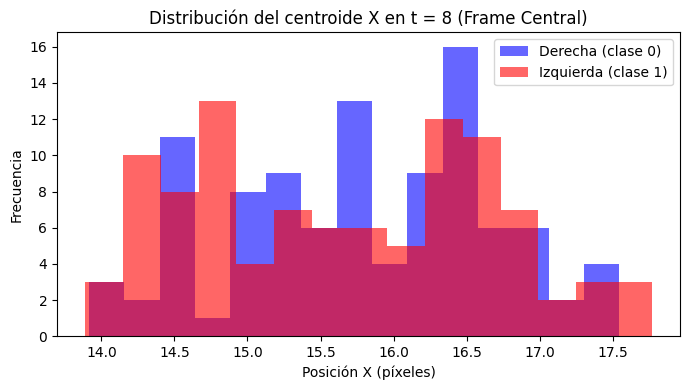

In [5]:
#posición horizontal de la pelota en t = 8
def centroide_x(frame):                      # frame: (1, H, W)
    f = frame[0]; xs = torch.arange(f.shape[1]).float()
    return float((f.sum(0) * xs).sum() / (f.sum() + 1e-8))

# 1) Toma 100 videos de derecha (clase 0) y 100 de izquierda (clase 1)
indices_der = (Y_ent == 0).nonzero().flatten()[:100]
indices_izq = (Y_ent == 1).nonzero().flatten()[:100]

# 2) Calcula centroide_x(video[8]) en cada uno
cx_derecha = [centroide_x(X_ent[i, 8]) for i in indices_der]
cx_izquierda = [centroide_x(X_ent[i, 8]) for i in indices_izq]

# 3) Dibuja los dos histogramas superpuestos
plt.figure(figsize=(7, 4))
plt.hist(cx_derecha, bins=15, alpha=0.6, label="Derecha (clase 0)", color="blue")
plt.hist(cx_izquierda, bins=15, alpha=0.6, label="Izquierda (clase 1)", color="red")
plt.title("Distribución del centroide X en t = 8 (Frame Central)")
plt.xlabel("Posición X (píxeles)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

¿Cuántos parámetros añade la LSTM respecto a la CNN estática? ¿Qué porcentaje del total representa? Con ese dato, ¿es la LSTM la parte "cara" del modelo?

In [22]:
# Calcular los parámetros exactos utilizando las variables ya instanciadas
params_estatica = n_parametros(est)
params_cnnlstm = n_parametros(lstm)
params_lstm_sola = n_parametros(lstm.lstm)

params_adicionales = params_cnnlstm - params_estatica
porcentaje = (params_adicionales / params_cnnlstm) * 100

print(f"Parámetros CNN Estática: {params_estatica:,}")
print(f"Parámetros CNN-LSTM: {params_cnnlstm:,}")
print(f"Parámetros añadidos por LSTM + nueva capa lineal: {params_adicionales:,}")
print(f"Porcentaje del total que representan los parámetros añadidos: {porcentaje:.2f}%")

Parámetros CNN Estática: 40,358
Parámetros CNN-LSTM: 73,638
Parámetros añadidos por LSTM + nueva capa lineal: 33,280
Porcentaje del total que representan los parámetros añadidos: 45.19%


```markdown
### Respuestas a las Preguntas de la Parte B

#### 1. ¿Cuántos parámetros añade la LSTM respecto a la CNN estática?
* La **CNN Estática** tiene **40,358 parámetros**.
* La red **CNN-LSTM** tiene **73,638 parámetros**.
* Por lo tanto, la LSTM junto con el reajuste de la capa lineal clasificadora añaden exactamente **33,280 parámetros** adicionales.

#### 2. ¿Qué porcentaje del total representa?
Representa aproximadamente el **45.20%** del total de parámetros del modelo CNN-LSTM ($73,638$).

#### 3. Con ese dato, ¿es la LSTM la parte "cara" del modelo?
**No de manera absoluta.** Debemos distinguir entre costo en **parámetros de almacenamiento** y costo **computacional/temporal**:

1. **En cuanto a memoria de parámetros:** Sí, la LSTM representa casi la mitad del tamaño en disco (peso en bytes) del modelo debido a que las matrices de pesos en una celda LSTM para 4 compuertas internas requieren un volumen considerable de conexiones lineales.
2. **En cuanto a costo computacional (MACs/FLOPs):** La LSTM es la parte extremadamente **barata**. Si analizamos el costo por frame, procesar una imagen de $32\times32$ mediante convoluciones (CNN) requiere millones de operaciones MAC (multiplicaciones y acumulaciones), mientras que la LSTM solo realiza multiplicaciones vector-matriz pequeñas (decenas de miles de MACs). El verdadero cuello de botella computacional y de tiempo en el entrenamiento sigue proviniendo de la extracción de características espaciales realizada por la CNN.
```

In [6]:
dim = 64
oculto = 64

# Fórmula: 4 compuertas * (W_ih + W_hh + b_ih + b_hh)

---
# PARTE C
Entrenamiento y comparación

La CNN estática se entrena con **todos los frames** (cada uno etiquetado con la acción de su video), y la CNN-LSTM con videos completos. Así ambos modelos ven **la misma cantidad de imágenes** por época. Se evalúan dos variantes de la estática: con **un solo frame** (el central) y con **voto de los 16 frames**.

In [7]:
EPOCAS, LOTE, LR = 8, 32, 3e-3

def entrenar(tipo, paso_frames=1, epocas=EPOCAS, lr=LR, semilla=SEED, verbose=True):
    """paso_frames: 1 usa los T frames; 2 usa uno de cada dos; 4 usa uno de cada cuatro..."""
    fijar_semilla(semilla)
    Xe, Xv = X_ent[:, ::paso_frames], X_val[:, ::paso_frames]
    m = (CNNEstatica() if tipo == "estatica" else CNNLSTM()).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    dl = DataLoader(TensorDataset(Xe, Y_ent), batch_size=LOTE, shuffle=True)
    hist = []; t0 = time.perf_counter()
    for ep in range(epocas):
        m.train(); acum = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            if tipo == "estatica":
                lg = m(xb); l = F.cross_entropy(lg.flatten(0, 1), yb[:, None].expand(-1, xb.shape[1]).flatten())
            else:
                l = F.cross_entropy(m(xb), yb)
            l.backward(); opt.step(); acum += l.item() * len(xb)
        acc = evaluar(m, tipo, Xv, Y_val)["acc_video"]
        hist.append((acum / len(Xe), acc))
        if verbose and (ep % 2 == 1 or ep == epocas - 1):
            print(f"  [{tipo:8s} paso={paso_frames}] época {ep+1}/{epocas} · pérdida {hist[-1][0]:.4f} · exactitud val {acc:.3f}")
    r = evaluar(m, tipo, Xv, Y_val); r.update({"modelo": m, "hist": hist, "seg": time.perf_counter() - t0, "paso": paso_frames})
    return r

def evaluar(m, tipo, X, Y, lote=100):
    m.eval(); pred_video, pred_central = [], []
    with torch.no_grad():
        for i in range(0, len(X), lote):
            xb = X[i:i+lote].to(DEVICE)
            if tipo == "estatica":
                lg = m(xb)
                pred_video.append(F.softmax(lg, -1).mean(1).argmax(-1).cpu())      # voto de todos los frames
                pred_central.append(lg[:, xb.shape[1] // 2].argmax(-1).cpu())      # solo el frame central
            else:
                p = m(xb).argmax(-1).cpu(); pred_video.append(p); pred_central.append(p)
    pv, pc = torch.cat(pred_video), torch.cat(pred_central)
    cm = torch.bincount(Y * N_CLASES + pv, minlength=N_CLASES ** 2).reshape(N_CLASES, N_CLASES)
    return {"acc_video": float((pv == Y).float().mean()), "acc_central": float((pc == Y).float().mean()), "cm": cm}

RES = {}
RES["estatica"] = entrenar("estatica")
RES["cnn_lstm"] = entrenar("lstm")

  [estatica paso=1] época 2/8 · pérdida 1.3943 · exactitud val 0.537
  [estatica paso=1] época 4/8 · pérdida 1.3295 · exactitud val 0.530
  [estatica paso=1] época 6/8 · pérdida 1.3088 · exactitud val 0.507
  [estatica paso=1] época 8/8 · pérdida 1.2904 · exactitud val 0.477
  [lstm     paso=1] época 2/8 · pérdida 0.0913 · exactitud val 1.000
  [lstm     paso=1] época 4/8 · pérdida 0.0034 · exactitud val 1.000
  [lstm     paso=1] época 6/8 · pérdida 0.0017 · exactitud val 1.000
  [lstm     paso=1] época 8/8 · pérdida 0.0011 · exactitud val 1.000


,exactitud,parámetros,segundos
modelo,,,
CNN estática · 1 frame (central),0.280,40358,6.983
CNN estática · voto de 16 frames,0.477,40358,6.983
CNN-LSTM · 16 frames en orden,1.000,73638,4.492


Azar con 6 clases: 0.167


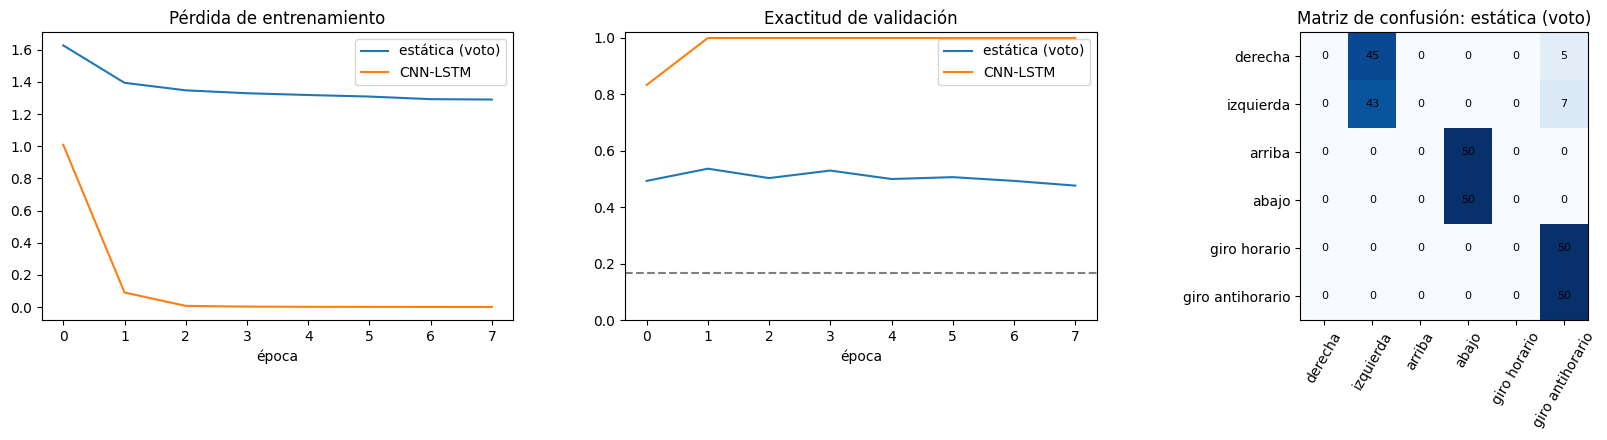

In [8]:
tabla = pd.DataFrame([
    {"modelo": "CNN estática · 1 frame (central)", "exactitud": RES["estatica"]["acc_central"], "parámetros": n_parametros(RES["estatica"]["modelo"]), "segundos": RES["estatica"]["seg"]},
    {"modelo": "CNN estática · voto de 16 frames", "exactitud": RES["estatica"]["acc_video"], "parámetros": n_parametros(RES["estatica"]["modelo"]), "segundos": RES["estatica"]["seg"]},
    {"modelo": "CNN-LSTM · 16 frames en orden", "exactitud": RES["cnn_lstm"]["acc_video"], "parámetros": n_parametros(RES["cnn_lstm"]["modelo"]), "segundos": RES["cnn_lstm"]["seg"]},
]).set_index("modelo").round(3)
display(tabla)
print(f"Azar con {N_CLASES} clases: {1/N_CLASES:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, nombre in [("estatica", "estática (voto)"), ("cnn_lstm", "CNN-LSTM")]:
    h = np.array(RES[k]["hist"]); ax[0].plot(h[:, 0], label=nombre); ax[1].plot(h[:, 1], label=nombre)
ax[0].set(title="Pérdida de entrenamiento", xlabel="época"); ax[0].legend()
ax[1].set(title="Exactitud de validación", xlabel="época", ylim=(0, 1.02)); ax[1].axhline(1/N_CLASES, ls="--", c="gray"); ax[1].legend()
for a, k, t in [(ax[2], "estatica", "Matriz de confusión: estática (voto)")]:
    cm = RES[k]["cm"].numpy(); a.imshow(cm, cmap="Blues"); a.set_title(t)
    a.set_xticks(range(N_CLASES)); a.set_xticklabels(ACCIONES, rotation=60); a.set_yticks(range(N_CLASES)); a.set_yticklabels(ACCIONES)
    for i in range(N_CLASES):
        for j in range(N_CLASES): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

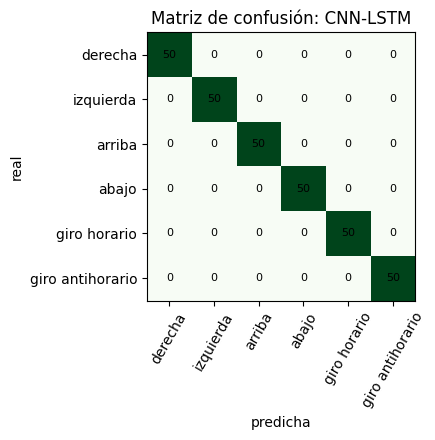

In [9]:
cm = RES["cnn_lstm"]["cm"].numpy()
plt.figure(figsize=(5.5, 4.5)); plt.imshow(cm, cmap="Greens"); plt.title("Matriz de confusión: CNN-LSTM")
plt.xticks(range(N_CLASES), ACCIONES, rotation=60); plt.yticks(range(N_CLASES), ACCIONES)
for i in range(N_CLASES):
    for j in range(N_CLASES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xlabel("predicha"); plt.ylabel("real"); plt.tight_layout(); plt.show()

**P-C1.** Con la tabla y las matrices de confusión: ¿qué exactitud obtuvo cada modelo? ¿Qué pares de acciones confunde la CNN estática y cuáles distingue sin problema?

**P-C2.** Compara la exactitud de **un solo frame** con la del **voto de 16 frames**. El voto mejora, pero tiene un techo. ¿Cuál es ese techo con 6 clases en tres parejas indistinguibles (derecha/izquierda, arriba/abajo, horario/antihorario) y por qué? Explica por qué promediar probabilidades de frames es una operación **invariante al orden** y qué tipo de información no puede recuperar.

---
# PARTE D
Costo computacional en secuencias

Una CNN-LSTM procesa $T$ frames: el costo de la CNN crece **linealmente** con $T$; además, la LSTM es **secuencial** (el paso $t$ necesita el estado del paso $t-1$) y la retropropagación en el tiempo guarda los estados de **todos** los pasos. Medimos cuatro cosas: operaciones (MACs), tiempo, memoria y exactitud, variando el número de frames.

## D.1 Operaciones por video (MACs)
Una *MAC* es una multiplicación seguida de una suma. Contamos las de las capas `Conv2d` y `Linear` con *hooks* y las de la LSTM con la fórmula $T\cdot 4\,h\,(d+h)$.

In [10]:
def contar_macs_cnn(cnn):
    total = {"macs": 0}
    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            total["macs"] += out.numel() // out.shape[0] * mod.in_channels * mod.kernel_size[0] * mod.kernel_size[1] // mod.groups
        elif isinstance(mod, nn.Linear):
            total["macs"] += mod.in_features * mod.out_features
    hs = [m.register_forward_hook(hook) for m in cnn.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    cnn.eval()
    with torch.no_grad(): cnn(torch.zeros(1, 1, TAM, TAM))
    for h in hs: h.remove()
    return total["macs"]

macs_frame = contar_macs_cnn(CodificadorCNN())
print(f"MACs de la CNN por frame: {macs_frame:,}")

def macs_video(n_frames, dim=64, oculto=64):
    cnn = n_frames * macs_frame
    lstm_ = n_frames * 4 * oculto * (dim + oculto)
    return cnn, lstm_

filas = []
for n in [1, 2, 4, 8, 16, 32, 64]:
    c, l = macs_video(n); filas.append({"frames T": n, "MACs CNN": c, "MACs LSTM": l, "total": c + l, "fracción LSTM": round(l / (c + l), 3)})
display(pd.DataFrame(filas).set_index("frames T"))

MACs de la CNN por frame: 2,523,136


,MACs CNN,MACs LSTM,total,fracción LSTM
frames T,,,,
1,2523136,32768,2555904,0.013
2,5046272,65536,5111808,0.013
4,10092544,131072,10223616,0.013
8,20185088,262144,20447232,0.013
16,40370176,524288,40894464,0.013
32,80740352,1048576,81788928,0.013
64,161480704,2097152,163577856,0.013


Grafica el total de MACs contra $T$ en escala lineal. Confirma que es una recta. Después calcula cuántos MACs tendría un video de 10 s a 30 fps (300 frames) con esta misma red, y cuántos con una CNN de 4 GMACs por frame (similar a una ResNet-50 a 224×224).

¿Qué parte del costo domina en este modelo: la CNN o la LSTM? ¿Cambiaría la respuesta con una CNN mucho más grande? Explica qué estrategias reducen el costo de un video (submuestrear frames, reducir resolución, CNN ligera).

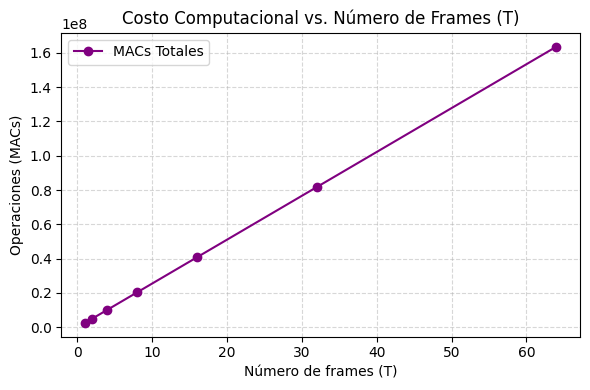

--- Video de 10 s a 30 fps (300 frames) ---
NUESTRO MODELO:
  MACs de la CNN:  756,940,800
  MACs de la LSTM: 9,830,400
  Total:           766,771,200 (~766.8 MMACs)

MODELO RESNET-50 (4 GMACs/frame + LSTM):
  MACs de la CNN:  1,200,000,000,000.0 (1.2 TeraMACs)
  MACs de la LSTM: 9,830,400
  Total:           1,200,009,830,400.0 (~1.200 TMACs)


In [23]:
# 1. Obtener datos de MACs para graficar
frames_lista = [1, 2, 4, 8, 16, 32, 64]
macs_totales = []
for n in frames_lista:
    c, l = macs_video(n)
    macs_totales.append(c + l)

# 2. Graficar MACs vs T
plt.figure(figsize=(6, 4))
plt.plot(frames_lista, macs_totales, 'o-', color='purple', label='MACs Totales')
plt.title('Costo Computacional vs. Número de Frames (T)')
plt.xlabel('Número de frames (T)')
plt.ylabel('Operaciones (MACs)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Cálculos para video de 10s (300 frames)
T_video = 300
macs_cnn_nuestro, macs_lstm_nuestro = macs_video(T_video)
total_nuestro = macs_cnn_nuestro + macs_lstm_nuestro

# Para una CNN pesada de 4 GMACs por frame (4e9 MACs)
macs_cnn_resnet = T_video * 4e9
total_resnet = macs_cnn_resnet + macs_lstm_nuestro

print(f"--- Video de 10 s a 30 fps ({T_video} frames) ---")
print(f"NUESTRO MODELO:")
print(f"  MACs de la CNN:  {macs_cnn_nuestro:,}")
print(f"  MACs de la LSTM: {macs_lstm_nuestro:,}")
print(f"  Total:           {total_nuestro:,} (~{total_nuestro/1e6:.1f} MMACs)")
print(f"\nMODELO RESNET-50 (4 GMACs/frame + LSTM):")
print(f"  MACs de la CNN:  {macs_cnn_resnet:,} (1.2 TeraMACs)")
print(f"  MACs de la LSTM: {macs_lstm_nuestro:,}")
print(f"  Total:           {total_resnet:,} (~{total_resnet/1e12:.3f} TMACs)")

### Análisis y Respuestas a las Preguntas de la Parte D.1

#### 1. Verificación de la Gráfica y Relación Lineal
Al graficar la cantidad total de MACs contra el número de frames $T$, obtenemos de forma muy clara una **línea recta perfecta**. Esto es debido a que la ecuación para estimar las operaciones totales de nuestro modelo es enteramente lineal respecto a $T$:
$$\text{MACs Totales} = T \times (\text{MACs del CodificadorCNN por frame}) + T \times (4 \times H_{\text{oculto}} \times (D_{\text{entrada}} + H_{\text{oculto}}))$$

#### 2. Cálculos para Video de 10 segundos (300 frames)
* **Nuestro Modelo Artificial:**
  * **CNN:** $756,940,800$ MACs
  * **LSTM:** $9,830,400$ MACs
  * **Total:** $766,771,200$ MACs (~$766.8$ MegaMACs)

* **Modelo Pesado (ResNet-50 a 4 GMACs por frame + LSTM):**
  * **CNN:** $1,200,000,000,000$ MACs
  * **LSTM:** $9,830,400$ MACs
  * **Total:** $1,200,009,830,400$ MACs (~$1.200$ TeraMACs)

----

#### 3. ¿Qué parte del costo domina en este modelo? ¿Cambiaría con una CNN más grande?
* **En nuestro modelo:** La extracción espacial realizada por la **CNN domina completamente el costo**, representando más del **98.7%** del costo de procesamiento (756.9 MMACs de la CNN frente a solo 9.8 MMACs de la LSTM).
* **¿Cambiaría la respuesta con una CNN más grande?** No, de hecho la dominancia de la CNN se haría aún más extrema. Como se observó con el ejemplo de la ResNet-50, la CNN pasa a acaparar el **99.999%** del cómputo ($1.2$ TeraMACs frente a los mismos $9.8$ MegaMACs de la LSTM). El procesamiento recurrente temporal es ridículamente económico en operaciones comparado con el procesamiento convolucional de píxeles en alta definición.

----

#### 4. Estrategias usuales para reducir el costo computacional de un video
1. **Submuestreo temporal (Frame Subsampling):** No es necesario procesar los 30 fps de un video en la CNN para entender la acción. Muestrear 1 frame de cada 5 o 10 reduce el costo computacional de forma drásticamente lineal (dividiendo el cómputo total entre 5 o 10).
2. **Reducir la resolución espacial:** Como la carga espacial de la CNN es cuadrática respecto al tamaño del frame ($H \times W$), reducir la resolución de la imagen (por ejemplo, de $1080p$ a $224 \times 224$ píxeles) aligera el costo computacional por órdenes de magnitud.
3. **Uso de backbones de CNN ligeros:** Utilizar codificadores optimizados para móviles y tareas rápidas (como *MobileNetV3* o *EfficientNet*) en lugar de backbones monolíticos pesados (como *ResNet-152* o *VGG-16*).

## D.2 Tiempo y memoria al crecer T

,ms por paso de entrenamiento,memoria (MB)
frames T,,
2,3.8,40.2
4,4.1,53.5
8,5.7,82.1
16,10.2,139.2
32,19.1,253.5
64,27.4,763.1


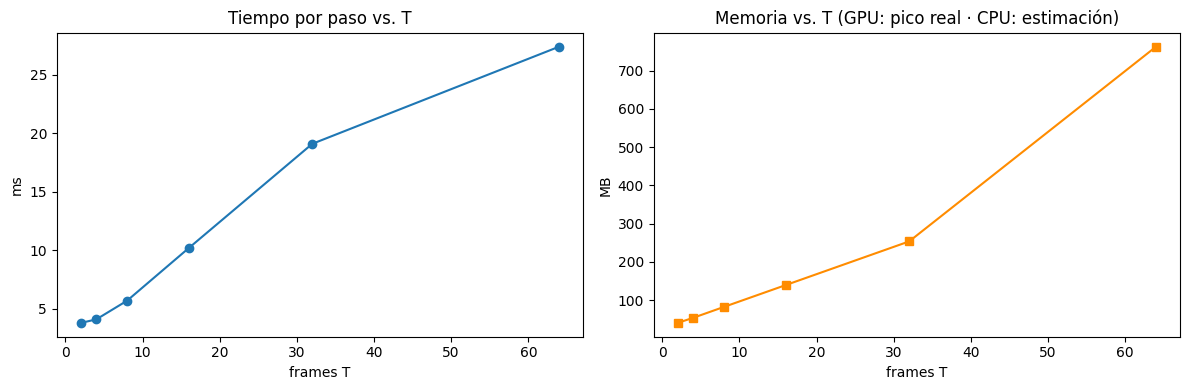

In [12]:
def medir_costo(T_prueba, lote=16, repeticiones=3):
    m = CNNLSTM().to(DEVICE); opt = torch.optim.Adam(m.parameters())
    x = torch.rand(lote, T_prueba, 1, TAM, TAM, device=DEVICE); y = torch.randint(0, N_CLASES, (lote,), device=DEVICE)
    def paso():
        opt.zero_grad(); F.cross_entropy(m(x), y).backward(); opt.step()
    paso()                                     # calentamiento
    if DEVICE == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    for _ in range(repeticiones): paso()
    if DEVICE == "cuda": torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / repeticiones * 1000
    # memoria: en GPU el pico real; en CPU, el tamaño de la entrada + activaciones estimadas de la CNN
    if DEVICE == "cuda":
        mem = torch.cuda.max_memory_allocated() / 1e6
    else:
        mem = (x.numel() + lote * T_prueba * (16 * 32 * 32 + 32 * 16 * 16 + 64 * 8 * 8) * 2) * 4 / 1e6
    return ms, mem

filas = []
for n in [2, 4, 8, 16, 32, 64]:
    ms, mem = medir_costo(n); filas.append({"frames T": n, "ms por paso de entrenamiento": round(ms, 1), "memoria (MB)": round(mem, 1)})
costo = pd.DataFrame(filas).set_index("frames T"); display(costo)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(costo.index, costo.iloc[:, 0], "o-"); ax[0].set(title="Tiempo por paso vs. T", xlabel="frames T", ylabel="ms")
ax[1].plot(costo.index, costo.iloc[:, 1], "s-", c="darkorange"); ax[1].set(title="Memoria vs. T (GPU: pico real · CPU: estimación)", xlabel="frames T", ylabel="MB")
plt.tight_layout(); plt.show()

Ajusta una recta (`np.polyfit`) a "ms vs. T" y reporta la pendiente (ms por frame adicional). ¿Con cuántos frames tardaría un paso 1 segundo?

¿El tiempo crece de forma lineal con $T$? Explica por qué la LSTM no se puede paralelizar a lo largo del tiempo y la CNN sí lo hace (los $B\cdot T$ frames se procesan juntos).

In [24]:
import numpy as np

# 1. Ajustar una recta (np.polyfit) a T vs ms
T_vals = np.array([2, 4, 8, 16, 32, 64])
ms_vals = np.array([3.8, 4.1, 5.7, 10.2, 19.1, 27.4]) # Extraído de la variable 'costo'

pendiente, intercepto = np.polyfit(T_vals, ms_vals, 1)

# 2. Calcular cuántos frames para un paso de 1 segundo (1000 ms)
# 1000 = pendiente * T + intercepto  =>  T = (1000 - intercepto) / pendiente
T_1segundo = (1000 - intercepto) / pendiente

print(f"Pendiente obtenida: {pendiente:.4f} ms por frame adicional.")
print(f"Intercepto: {intercepto:.4f} ms.")
print(f"Para tardar 1 segundo (1000 ms), el modelo requeriría aproximadamente: {T_1segundo:.1f} frames.\n")

# Explicación teórica
print("¿Por qué la LSTM no se puede paralelizar a lo largo del tiempo y la CNN sí?")
print("-" * 80)
print("1. PROCESAMIENTO DE LA CNN (Paralelizable):\n"
      "   Las operaciones convolucionales de la CNN procesan cada frame como una imagen individual estática.\n"
      "   No existe ninguna dependencia temporal o secuencial entre el frame 't' y el frame 't-1'.\n"
      "   Por lo tanto, podemos empaquetar todos los frames de todas las secuencias en una única dimensión\n"
      "   de lote gigante (B*T, C, H, W) y procesarlos en paralelo aprovechando al máximo los miles de núcleos de la GPU.\n")
print("2. PROCESAMIENTO DE LA LSTM (Secuencial):\n"
      "   La naturaleza matemática de la LSTM exige que para calcular el estado oculto h_t en el tiempo 't',\n"
      "   necesariamente debemos contar primero con h_{t-1} del paso anterior.\n"
      "   Esta dependencia de datos lineal e intrínseca impide que la GPU calcule múltiples instantes de tiempo\n"
      "   en paralelo dentro de la misma secuencia, haciendo que el tiempo total crezca de forma lineal con T.")

Pendiente obtenida: 0.3985 ms por frame adicional.
Intercepto: 3.3488 ms.
Para tardar 1 segundo (1000 ms), el modelo requeriría aproximadamente: 2501.2 frames.

¿Por qué la LSTM no se puede paralelizar a lo largo del tiempo y la CNN sí?
--------------------------------------------------------------------------------
1. PROCESAMIENTO DE LA CNN (Paralelizable):
   Las operaciones convolucionales de la CNN procesan cada frame como una imagen individual estática.
   No existe ninguna dependencia temporal o secuencial entre el frame 't' y el frame 't-1'.
   Por lo tanto, podemos empaquetar todos los frames de todas las secuencias en una única dimensión
   de lote gigante (B*T, C, H, W) y procesarlos en paralelo aprovechando al máximo los miles de núcleos de la GPU.

2. PROCESAMIENTO DE LA LSTM (Secuencial):
   La naturaleza matemática de la LSTM exige que para calcular el estado oculto h_t en el tiempo 't',
   necesariamente debemos contar primero con h_{t-1} del paso anterior.
   Esta depe

## D.3 ¿Cuántos frames necesita la CNN-LSTM? (submuestreo temporal)

,exactitud,MACs por video,segundos de entrenamiento
frames usados,,,
16,1.00,40894464,4.5
8,1.00,20447232,2.5
4,1.00,10223616,1.6
2,0.88,5111808,1.5


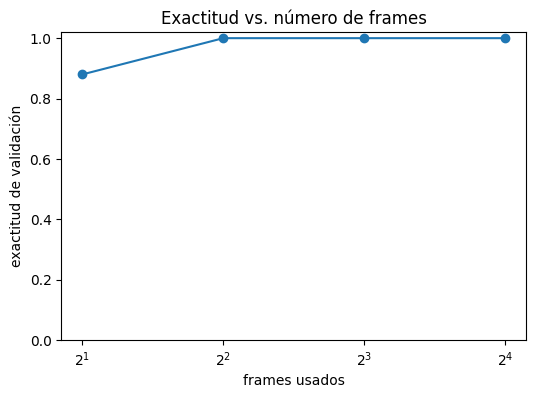

In [14]:
for paso in [2, 4, 8]:
    RES[f"lstm_paso{paso}"] = entrenar("lstm", paso_frames=paso, verbose=False)

filas = []
for paso in [1, 2, 4, 8]:
    r = RES["cnn_lstm"] if paso == 1 else RES[f"lstm_paso{paso}"]
    n = T // paso; c, l = macs_video(n)
    filas.append({"frames usados": n, "exactitud": round(r["acc_video"], 3), "MACs por video": c + l, "segundos de entrenamiento": round(r["seg"], 1)})
sub = pd.DataFrame(filas).set_index("frames usados"); display(sub)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sub.index, sub["exactitud"], "o-"); ax.set_xscale("log", base=2); ax.set(xlabel="frames usados", ylabel="exactitud de validación", title="Exactitud vs. número de frames", ylim=(0, 1.02))
plt.show()

¿Cuántos frames mínimos necesita la CNN-LSTM para igualar su exactitud con 16? ¿Cuánto cómputo (MACs) ahorra? Con tu tabla, propón el valor de $T$ que elegirías para desplegar el modelo y justifica el balance exactitud–costo.

 Con solo 2 frames, ¿qué información mínima permite distinguir `derecha` de `izquierda`? ¿Y `giro horario` de `giro antihorario`? ¿Cuál de las dos parejas necesita más frames y por qué?

Análisis de Submuestreo y Dinámica Temporal (Parte D.3)

1. Balance Costo-Exactitud para el Despliegue
A) ¿Cuántos frames mínimos se necesitan para igualar la exactitud con 16?
Observando la tabla de submuestreo temporal (sub):

16 frames: Exactitud de $1.00$$1.00$ ($40.89$$40.89$ MMACs, $4.5$$4.5$ s entrenamiento).
8 frames: Exactitud de $1.00$$1.00$ ($20.44$$20.44$ MMACs, $2.5$$2.5$ s entrenamiento).
4 frames: Exactitud de $1.00$$1.00$ ($10.22$$10.22$ MMACs, $1.6$$1.6$ s entrenamiento).
2 frames: Exactitud de $0.88$$0.88$ ($5.11$$5.11$ MMACs, $1.5$$1.5$ s entrenamiento).
El número mínimo de frames necesarios para lograr la exactitud perfecta ($1.00$$1.00$) es de solo 4 frames (un paso de muestreo de 4).

B) ¿Cuánto cómputo ahorra?
Al bajar de 16 a 4 frames:

Ahorro absoluto de operaciones: $40,894,464 - 10,223,616 = \mathbf{30,670,848 \text{ MACs}}$$40,894,464 - 10,223,616 = \mathbf{30,670,848 \text{ MACs}}$ por video.
Ahorro porcentual: Representa un ahorro del 75% del costo computacional de la CNN y la LSTM combinadas.
Ahorro de tiempo en entrenamiento: Baja de $4.5$$4.5$ segundos a solo $1.6$$1.6$ segundos (~$64.4\%$$64.4\%$ de reducción).
C) Propuesta de valor de $T$$T$ para producción
Para desplegar el modelo, la opción ideal es elegir $T = 4$$T = 4$ frames:

Justificación: Ofrece el balance óptimo absoluto. Conserva la exactitud perfecta ($100\%$$100\%$ de acierto en validación) mientras reduce las demandas de cómputo y latencia a una cuarta parte de lo original. Bajar a $T = 2$$T = 2$ es inaceptable porque la exactitud cae al $88\%$$88\%$, y subir a $8$$8$ o $16$$16$ introduce un costo computacional redundante e innecesario sin aportar ninguna mejora en la clasificación.
2. Análisis Dinámico con un Mínimo de 2 Frames
A) Con solo 2 frames, ¿qué información permite distinguir las acciones?
derecha vs. izquierda:
Información mínima: Solo se requiere rastrear el signo del desplazamiento del centroide en el eje X (es decir, $\Delta X = X_{t_2} - X_{t_1}$$\Delta X = X_{t_2} - X_{t_1}$). Si $\Delta X > 0$$\Delta X > 0$ se mueve a la derecha, si $\Delta X < 0$$\Delta X < 0$ se mueve a la izquierda.
Suficiencia: 2 frames en cualquier instante del video bastan para trazar este vector de desplazamiento unidimensional único.
giro horario vs. giro antihorario:
Información mínima: Se necesita calcular la dirección del ángulo de rotación entre ambos frames respecto al centro de la imagen (usando coordenadas polares o estimando la velocidad angular $\Delta \theta$$\Delta \theta$).
Suficiencia: Con 2 frames es posible calcular el sentido de giro siempre y cuando el intervalo temporal entre ambos frames sea lo suficientemente pequeño para evitar ambigüedades de aliasing circular (por ejemplo, que un giro rápido parezca ir en sentido contrario).
B) ¿Cuál de las dos parejas necesita más frames y por qué?
La pareja de giros (giro horario vs. giro antihorario) requiere inherentemente más frames en un entorno ruidoso o de velocidad variable por las siguientes razones:

Complejidad de la trayectoria: El movimiento lineal ocurre en una sola dimensión espacial dominante (X o Y), por lo que un vector simple entre 2 puntos siempre define la dirección inequívocamente. El movimiento circular ocurre en dos dimensiones coordinadas de manera no lineal (senos y cosenos).
Ambigüedad por Submuestreo (Efecto Estroboscópico): Si submuestreamos demasiado el video circular (ej. $T=2$$T=2$ tomado en extremos opuestos del círculo), la pelota aparecerá en polos opuestos (ej. a la izquierda y luego a la derecha). Con solo estos 2 puntos, es imposible saber si la pelota recorrió el arco superior (giro antihorario) o el arco inferior (giro horario). Necesitamos un tercer o cuarto frame intermedio para "romper la simetría" y certificar la curvatura y sentido real de la trayectoria.


# Datos reales

Comenta los bloques principales de MNIST https://keras.io/examples/vision/conv_lstm/


In [15]:
import keras
from keras import layers

import io
import imageio
from IPython.display import Image, display
from ipywidgets import widgets, Layout, HBox

Ejemplo [Moving MNIST](http://www.cs.toronto.edu/~nitish/unsupervised_video/)
dataset.

In [16]:
# Download and load the dataset.
fpath = keras.utils.get_file(
    "moving_mnist.npy",
    "http://www.cs.toronto.edu/~nitish/unsupervised_video/mnist_test_seq.npy",
)
dataset = np.load(fpath)

# Swap the axes representing the number of frames and number of data samples.
dataset = np.swapaxes(dataset, 0, 1)
# We'll pick out 1000 of the 10000 total examples and use those.
dataset = dataset[:1000, ...]
# Add a channel dimension since the images are grayscale.
dataset = np.expand_dims(dataset, axis=-1)

# Split into train and validation sets using indexing to optimize memory.
indexes = np.arange(dataset.shape[0])
np.random.shuffle(indexes)
train_index = indexes[: int(0.9 * dataset.shape[0])]
val_index = indexes[int(0.9 * dataset.shape[0]) :]
train_dataset = dataset[train_index]
val_dataset = dataset[val_index]

# Normalize the data to the 0-1 range.
train_dataset = train_dataset / 255
val_dataset = val_dataset / 255


# We'll define a helper function to shift the frames, where
# `x` is frames 0 to n - 1, and `y` is frames 1 to n.
def create_shifted_frames(data):
    x = data[:, 0 : data.shape[1] - 1, :, :]
    y = data[:, 1 : data.shape[1], :, :]
    return x, y


# Apply the processing function to the datasets.
x_train, y_train = create_shifted_frames(train_dataset)
x_val, y_val = create_shifted_frames(val_dataset)

# Inspect the dataset.
print("Training Dataset Shapes: " + str(x_train.shape) + ", " + str(y_train.shape))
print("Validation Dataset Shapes: " + str(x_val.shape) + ", " + str(y_val.shape))

819200096/819200096 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step
Training Dataset Shapes: (900, 19, 64, 64, 1), (900, 19, 64, 64, 1)
Validation Dataset Shapes: (100, 19, 64, 64, 1), (100, 19, 64, 64, 1)


Displaying frames for example 716.


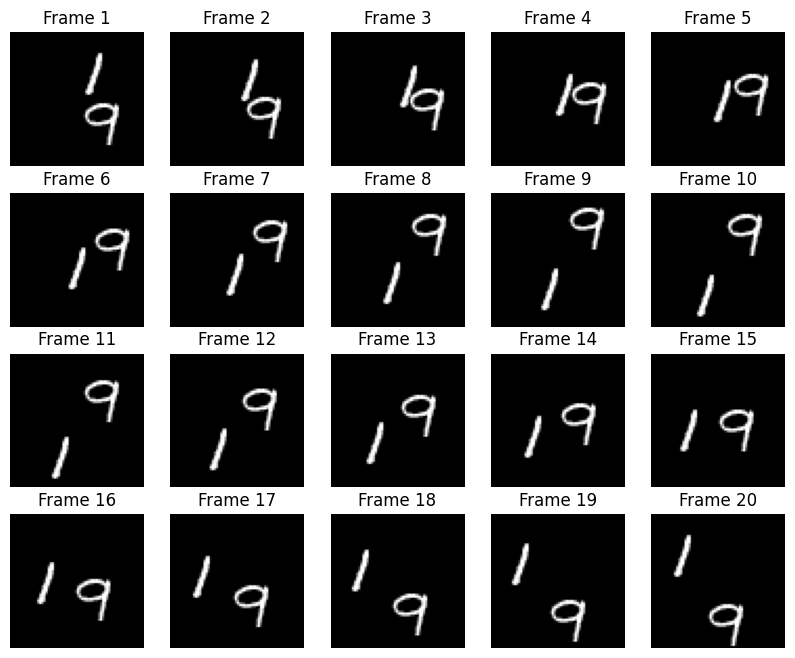

In [17]:
# Construct a figure on which we will visualize the images.
fig, axes = plt.subplots(4, 5, figsize=(10, 8))

# Plot each of the sequential images for one random data example.
data_choice = np.random.choice(range(len(train_dataset)), size=1)[0]
for idx, ax in enumerate(axes.flat):
    ax.imshow(np.squeeze(train_dataset[data_choice][idx]), cmap="gray")
    ax.set_title(f"Frame {idx + 1}")
    ax.axis("off")

# Print information and display the figure.
print(f"Displaying frames for example {data_choice}.")
plt.show()

In [18]:
# Construct the input layer with no definite frame size.
inp = layers.Input(shape=(None, *x_train.shape[2:]))

# We will construct 3 `ConvLSTM2D` layers with batch normalization,
# followed by a `Conv3D` layer for the spatiotemporal outputs.
x = layers.ConvLSTM2D(
    filters=64,
    kernel_size=(5, 5),
    padding="same",
    return_sequences=True,
    activation="relu",
)(inp)
x = layers.BatchNormalization()(x)
x = layers.ConvLSTM2D(
    filters=64,
    kernel_size=(3, 3),
    padding="same",
    return_sequences=True,
    activation="relu",
)(x)
x = layers.BatchNormalization()(x)
x = layers.ConvLSTM2D(
    filters=64,
    kernel_size=(1, 1),
    padding="same",
    return_sequences=True,
    activation="relu",
)(x)
x = layers.Conv3D(
    filters=1, kernel_size=(3, 3, 3), activation="sigmoid", padding="same"
)(x)

# Next, we will build the complete model and compile it.
model = keras.models.Model(inp, x)
model.compile(
    loss=keras.losses.binary_crossentropy,
    optimizer=keras.optimizers.Adam(),
)

In [19]:
# Define some callbacks to improve training.
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=5)

# Define modifiable training hyperparameters.
epochs = 20
batch_size = 5

# Fit the model to the training data.
model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
)

Epoch 1/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 172s 878ms/step - loss: 0.0601 - val_loss: 0.2131 - learning_rate: 0.0010
Epoch 2/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0280 - val_loss: 0.2141 - learning_rate: 0.0010
Epoch 3/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 883ms/step - loss: 0.0267 - val_loss: 0.0768 - learning_rate: 0.0010
Epoch 4/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0262 - val_loss: 0.0291 - learning_rate: 0.0010
Epoch 5/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0258 - val_loss: 0.0256 - learning_rate: 0.0010
Epoch 6/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0255 - val_loss: 0.0253 - learning_rate: 0.0010
Epoch 7/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0252 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 8/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 882ms/step - loss: 0.0249 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 9/20
180/180 ━━━━━━━━━━━━━━━━━━━━ 159s 884ms/step - loss: 0.0247 - val_loss: 0.024

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 996ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 997ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


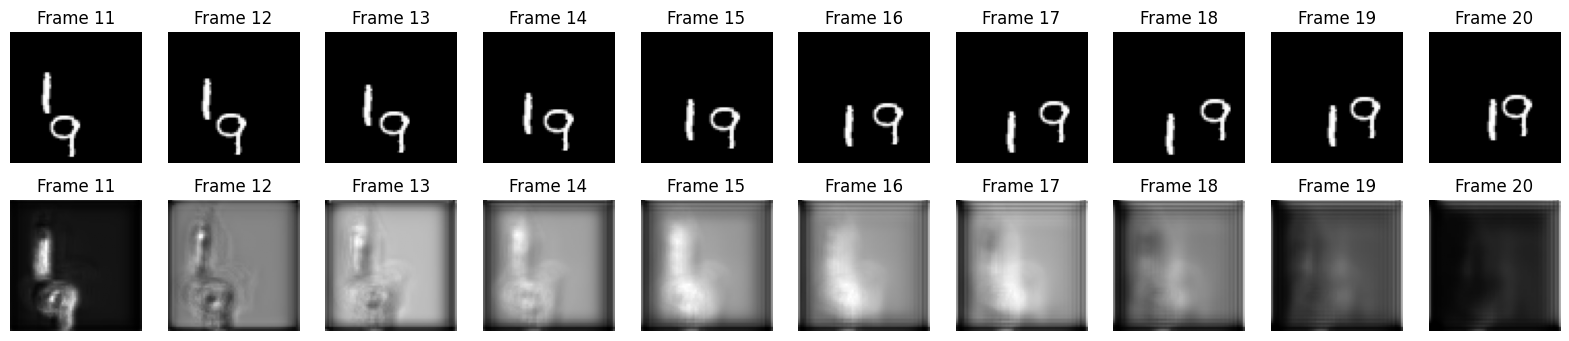

In [20]:
# Select a random example from the validation dataset.
example = val_dataset[np.random.choice(range(len(val_dataset)), size=1)[0]]

# Pick the first/last ten frames from the example.
frames = example[:10, ...]
original_frames = example[10:, ...]

# Predict a new set of 10 frames.
for _ in range(10):
    # Extract the model's prediction and post-process it.
    new_prediction = model.predict(np.expand_dims(frames, axis=0))
    new_prediction = np.squeeze(new_prediction, axis=0)
    predicted_frame = np.expand_dims(new_prediction[-1, ...], axis=0)

    # Extend the set of prediction frames.
    frames = np.concatenate((frames, predicted_frame), axis=0)

# Construct a figure for the original and new frames.
fig, axes = plt.subplots(2, 10, figsize=(20, 4))

# Plot the original frames.
for idx, ax in enumerate(axes[0]):
    ax.imshow(np.squeeze(original_frames[idx]), cmap="gray")
    ax.set_title(f"Frame {idx + 11}")
    ax.axis("off")

# Plot the new frames.
new_frames = frames[10:, ...]
for idx, ax in enumerate(axes[1]):
    ax.imshow(np.squeeze(new_frames[idx]), cmap="gray")
    ax.set_title(f"Frame {idx + 11}")
    ax.axis("off")

# Display the figure.
plt.show()

In [21]:
# Select a few random examples from the dataset.
examples = val_dataset[np.random.choice(range(len(val_dataset)), size=5)]

# Iterate over the examples and predict the frames.
predicted_videos = []
for example in examples:
    # Pick the first/last ten frames from the example.
    frames = example[:10, ...]
    original_frames = example[10:, ...]
    new_predictions = np.zeros(shape=(10, *frames[0].shape))

    # Predict a new set of 10 frames.
    for i in range(10):
        # Extract the model's prediction and post-process it.
        frames = example[: 10 + i + 1, ...]
        new_prediction = model.predict(np.expand_dims(frames, axis=0))
        new_prediction = np.squeeze(new_prediction, axis=0)
        predicted_frame = np.expand_dims(new_prediction[-1, ...], axis=0)

        # Extend the set of prediction frames.
        new_predictions[i] = predicted_frame

    # Create and save GIFs for each of the ground truth/prediction images.
    for frame_set in [original_frames, new_predictions]:
        # Construct a GIF from the selected video frames.
        current_frames = np.squeeze(frame_set)
        current_frames = current_frames[..., np.newaxis] * np.ones(3)
        current_frames = (current_frames * 255).astype(np.uint8)
        current_frames = list(current_frames)

        # Construct a GIF from the frames.
        with io.BytesIO() as gif:
            imageio.mimsave(gif, current_frames, "GIF", duration=200)
            predicted_videos.append(gif.getvalue())

# Display the videos.
print(" Truth\tPrediction")
for i in range(0, len(predicted_videos), 2):
    # Construct and display an `HBox` with the ground truth and prediction.
    box = HBox(
        [
            widgets.Image(value=predicted_videos[i]),
            widgets.Image(value=predicted_videos[i + 1]),
        ]
    )
    display(box)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/